**Ques 15. Implement a basic feedforward neural network (FNN) and perform following operations:<br>
a) Build a 2-layer NN using Keras/TensorFlow<br>
b) Train on the MNIST dataset for digit classification.<br>
Analyze the imapct of activation functions (ReLU vs. Sigmoid).<br>**

**NAME:- Ishita Dasila** &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; **UNIVERSITY ROLL NUMBER:- 2023869** 

In [11]:
import tensorflow as tf

In [13]:
mnist_data=tf.keras.datasets.mnist

In [15]:
(train_images,train_labels),(test_images,test_labels)=mnist_data.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [17]:
len(train_images)

60000

In [19]:
len(test_images)

10000

In [25]:
#select any random pixel image
import numpy as np
np.set_printoptions(linewidth=150)
print(train_images[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 182 247 241   0   

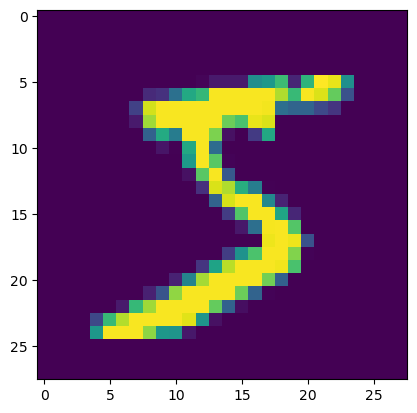

In [29]:
#visualizing the image
import matplotlib.pyplot as plt
plt.imshow(train_images[0])
plt.show()

In [33]:
train_images=train_images/255.0

In [35]:
test_images=test_images/255.0

In [37]:
print(train_images[0])

[[0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.         0.         0.         0.         0.         0.         0.

In [41]:
#create a deep neural network
model=tf.keras.Sequential([
    tf.keras.Input(shape=(28,28,1)),
    tf.keras.layers.Conv2D(32,(3,3),activation="relu"),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256,activation="relu"),
    tf.keras.layers.Dense(128,activation="relu"),
    tf.keras.layers.Dense(64,activation="relu"),
    tf.keras.layers.Dense(32,activation="relu"),
    tf.keras.layers.Dense(10,activation="softmax")
])

In [43]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [45]:
model.fit(train_images,train_labels,validation_data=(test_images,test_labels),epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 52s 27ms/step - accuracy: 0.9477 - loss: 0.1731 - val_accuracy: 0.9756 - val_loss: 0.0734
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 84s 28ms/step - accuracy: 0.9833 - loss: 0.0561 - val_accuracy: 0.9800 - val_loss: 0.0655
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 55s 29ms/step - accuracy: 0.9909 - loss: 0.0304 - val_accuracy: 0.9816 - val_loss: 0.0649
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 53s 28ms/step - accuracy: 0.9921 - loss: 0.0241 - val_accuracy: 0.9845 - val_loss: 0.0625
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 54s 29ms/step - accuracy: 0.9951 - loss: 0.0164 - val_accuracy: 0.9840 - val_loss: 0.0592


In [47]:
model.evaluate(test_images,test_labels)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9840 - loss: 0.0592


[0.05915035307407379, 0.984000027179718]

In [51]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

In [53]:
# Get predictions
y_pred = np.argmax(model.predict(test_images), axis=1)
y_true = test_labels

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


In [55]:
# Accuracy
acc = accuracy_score(y_pred, y_true)
print(f"Accuracy of the proposed model:{acc}")

Accuracy of the proposed model:0.984


In [57]:
# Confusion Matrix
cm = confusion_matrix(y_pred, y_true)
print(cm)

[[ 973    0    0    0    0    2    5    1    3    1]
 [   0 1119    0    0    0    0    2    0    0    3]
 [   2    5 1023    3    2    0    0    4    2    1]
 [   0    0    0  990    0   13    1    0    2    2]
 [   0    0    0    0  961    0    3    0    1    3]
 [   0    0    0    2    0  871    2    0    0    1]
 [   2    1    0    0    4    1  942    0    0    0]
 [   1    7    8   11    0    0    0 1020    7    8]
 [   2    3    1    2    1    4    3    1  952    1]
 [   0    0    0    2   14    1    0    2    7  989]]


In [59]:
# Classification Report
output = ["0","1","2","3","4","5","6","7","8","9"]
cr = classification_report(y_pred, y_true, target_names=output)
print(cr)

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       985
           1       0.99      1.00      0.99      1124
           2       0.99      0.98      0.99      1042
           3       0.98      0.98      0.98      1008
           4       0.98      0.99      0.99       968
           5       0.98      0.99      0.99       876
           6       0.98      0.99      0.99       950
           7       0.99      0.96      0.98      1062
           8       0.98      0.98      0.98       970
           9       0.98      0.97      0.98      1015

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



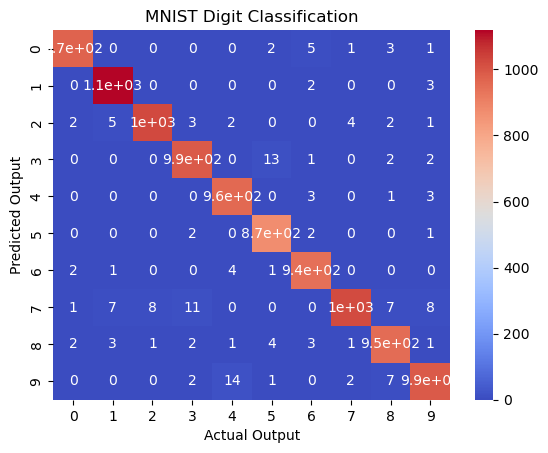

In [61]:
# Heatmap
sns.heatmap(cm, cmap='coolwarm', annot=True, xticklabels=output, yticklabels=output)
plt.xlabel("Actual Output")
plt.ylabel("Predicted Output")
plt.title("MNIST Digit Classification")
plt.show()